<a href="https://colab.research.google.com/github/lohithharish798-creator/FLOWCAST-AI-POWERED-SMART-TRAFFIC-FLOW-PREDICTION-PLATFORM/blob/main/FLOWCAST_AI_POWERED_SMART_TRAFFIC_FLOW_PREDICTION_PLATFORM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import json
import numpy as np

# 1. Load calendar_events.csv (smallest table, no defects)[span_2](start_span)[span_2](end_span)[span_3](start_span)[span_3](end_span)
df_calendar = pd.read_csv('/content/sample_data/calendar_events.csv')

# 2. Load weather_observations.csv
df_weather = pd.read_csv('/content/sample_data/weather_observations.csv')

# 3. Load traffic_sensor_log.csv (primary table / modeling grain)[span_4](start_span)[span_4](end_span)
df_traffic = pd.read_csv('/content/sample_data/traffic_sensor_log.csv')

print("Loaded raw datasets successfully!")
print(f"Calendar shape: {df_calendar.shape}")
print(f"Weather shape: {df_weather.shape}")
print(f"Traffic shape: {df_traffic.shape}")

Loaded raw datasets successfully!
Calendar shape: (151, 6)
Weather shape: (10872, 7)
Traffic shape: (178468, 17)


In [3]:
# Parse weather date from DD/MM/YYYY to standard YYYY-MM-DD
df_weather["date"] = pd.to_datetime(
    df_weather["date"], format="%d/%m/%Y"
).dt.date


# Harmonize weather_condition into a controlled vocabulary: Clear, Cloudy, Rain, Fog
def clean_weather_condition(val):
  if pd.isna(val):
    return "Unknown"
  val_clean = str(val).strip().lower()
  if "rain" in val_clean:
    return "Rain"
  elif "cloud" in val_clean:
    return "Cloudy"
  elif "fog" in val_clean:
    return "Fog"
  elif "clear" in val_clean or "sun" in val_clean:
    return "Clear"
  else:
    return "Clear"  # Default fallback or handle as needed


df_weather["weather_condition"] = df_weather["weather_condition"].apply(
    clean_weather_condition
)

# Prepare an hour matching key for half-hourly traffic alignment
# Weather 'time' is clock hour (e.g., '01:00')
df_weather["hour"] = pd.to_datetime(
    df_weather["time"], format="%H:%M"
).dt.hour

print("Weather data cleaned and harmonized successfully.")

Weather data cleaned and harmonized successfully.


In [6]:
# 1. De-duplicate on road_id + date + time
initial_len = len(df_traffic)
df_traffic = df_traffic.drop_duplicates(subset=["road_id", "date", "time"])
print(f"Removed {initial_len - len(df_traffic)} duplicate rows.")

# 2. Handle Impossible Outliers
# Replace negative traffic volume, speeds > 200 km/h, and occupancy > 100% with NaN
df_traffic.loc[df_traffic["traffic_volume"] < 0, "traffic_volume"] = np.nan
df_traffic.loc[df_traffic["avg_speed" ] > 200, "avg_speed"] = np.nan
df_traffic.loc[df_traffic["occupancy"] > 100, "occupancy"] = np.nan

# 3. Parse Nested JSON field: vehicle_type_dist
def parse_vehicle_dist(val):
  try:
    data = json.loads(val.replace("'", '"'))
    return pd.Series(data)
  except Exception:
    return pd.Series({"2W": np.nan, "Car": np.nan, "LCV": np.nan, "HCV": np.nan})


vehicle_features = df_traffic["vehicle_type_dist"].apply(parse_vehicle_dist)
df_traffic = pd.concat([df_traffic, vehicle_features], axis=1)

# 4. Derive Missing Congestion Level
# Parse traffic date
df_traffic["date"] = pd.to_datetime(df_traffic["date"]).dt.date

# Extract hour from traffic time to align with hourly weather later
df_traffic["hour"] = pd.to_datetime(df_traffic["time"], format="%H:%M").dt.hour


def derive_congestion(row):
  # If congestion_level is already present and valid, keep it
  if pd.notna(row["congestion_level"]) and str(row["congestion_level"]).strip():
    return row["congestion_level"]

  # Compute V/C ratio: traffic_volume / (road_capacity / 2)
  if pd.isna(row["traffic_volume"]) or pd.isna(row["road_capacity"]) or row["road_capacity"] == 0:
    return np.nan

  vc_ratio = row["traffic_volume"] / (row["road_capacity"] / 2.0)

  if vc_ratio < 0.50:
    return "Free-flow"
  elif vc_ratio <= 0.79:
    return "Moderate"
  elif vc_ratio <= 0.99:
    return "Heavy"
  else:
    return "Severe"


df_traffic["congestion_level"] = df_traffic.apply(derive_congestion, axis=1)
print("Traffic sensor logs cleaned and features derived.")

Removed 0 duplicate rows.
Traffic sensor logs cleaned and features derived.


In [8]:
# 1. Merge Weather onto Traffic using station_id, date, and hour
merged_df = pd.merge(
    df_traffic,
    df_weather,
    left_on=["weather_station_id", "date", "hour"],
    right_on=["station_id", "date", "hour"],
    how="left",
    suffixes=("", "_weather"),
)

# Drop redundant station_id column from weather table
if "station_id_weather" in merged_df.columns:
  merged_df = merged_df.drop(columns=["station_id_weather"])

# 2. Merge Calendar Events onto Traffic using date
merged_df = pd.merge(merged_df, df_calendar, on="date", how="left")

print(f"Merged dataset shape: {merged_df.shape}")

Merged dataset shape: (176701, 37)


In [10]:
import os

# Check remaining missing values across key targets
print("Missing values in key columns:")
print(
    merged_df[
        ["traffic_volume", "congestion_level", "avg_speed", "temperature"]
    ].isnull().sum()
)

# Ensure destination directory exists
os.makedirs("data/processed", exist_ok=True)

# Export to final analysis-ready CSV
merged_df.to_csv("data/processed/flowcast_analysis_ready.csv", index=False)
print("Pipeline complete! Exported to data/processed/flowcast_analysis_ready.csv")

Missing values in key columns:
traffic_volume      4587
congestion_level     681
avg_speed           4579
temperature         2708
dtype: int64
Pipeline complete! Exported to data/processed/flowcast_analysis_ready.csv


In [11]:
import pandas as pd

# Load the processed dataset if starting fresh
df = pd.read_csv("data/processed/flowcast_analysis_ready.csv")

# Ensure date and time columns are properly formatted
df["date"] = pd.to_datetime(df["date"])
df["datetime"] = pd.to_datetime(
    df["date"].astype(str) + " " + df["time"], format="%Y-%m-%d %H:%M"
)

# Sort chronologically by road segment and timestamp (critical for time-series / lag features)
df = df.sort_values(by=["road_id", "datetime"]).reset_index(drop=True)

# 1. Temporal Feature Engineering
df["hour_of_day"] = df["datetime"].dt.hour
df["minute_of_hour"] = df["datetime"].dt.minute
df["day_of_week"] = df["datetime"].dt.dayofweek  # 0 = Monday, 6 = Sunday
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)
df["month"] = df["datetime"].dt.month

# 2. Fill remaining text/categorical blanks if any
df["holiday_name"] = df["holiday_name"].fillna("None")
df["event_name"] = df["event_name"].fillna("None")
df["weather_condition"] = df["weather_condition"].fillna("Clear")

print("Temporal features engineered successfully.")

Temporal features engineered successfully.


In [12]:
# Create lag features per road segment (e.g., traffic volume 30 mins ago and 1 hour ago)
df["traffic_vol_lag_30m"] = df.groupby("road_id")["traffic_volume"].shift(1)
df["traffic_vol_lag_1h"] = df.groupby("road_id")["traffic_volume"].shift(2)

# Rolling window average (e.g., 2-hour moving average of volume per road)
df["traffic_vol_rolling_2h"] = (
    df.groupby("road_id")["traffic_volume"]
    .shift(1)
    .rolling(window=4)
    .mean()
)

# Drop rows where lag features resulted in NaNs (or handle them via imputation)
df_model = df.dropna(subset=["traffic_vol_lag_1h", "traffic_volume"]).copy()
print(f"Dataset shape after creating lag features: {df_model.shape}")

Dataset shape after creating lag features: (167603, 46)


In [13]:
# Define cutoff date for training vs testing (e.g., train on Jan-Apr, test on May)
split_date = pd.to_datetime("2025-05-01")

train_df = df_model[df_model["date"] < split_date]
test_df = df_model[df_model["date"] >= split_date]

print(f"Training set records: {len(train_df)}")
print(f"Testing set records: {len(test_df)}")

# Define feature columns for modelling
feature_cols = [
    "latitude",
    "longitude",
    "hour",
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "month",
    "temperature",
    "rainfall",
    "visibility",
    "public_holiday",
    "event_flag",
    "roadwork_flag",
    "road_capacity",
    "signal_timing",
    "2W",
    "Car",
    "LCV",
    "HCV",
    "traffic_vol_lag_30m",
    "traffic_vol_lag_1h",
]

# Targets per PRD requirements
target_regression = "traffic_volume"  # Primary regression target[span_2](start_span)[span_2](end_span)
target_classification = "congestion_level"  # Primary classification target[span_3](start_span)[span_3](end_span)

X_train = train_df[feature_cols]
y_train_reg = train_df[target_regression]
y_train_clf = train_df[target_classification]

X_test = test_df[feature_cols]
y_test_reg = test_df[target_regression]
y_test_clf = test_df[target_classification]

print("Train and test feature matrices prepared successfully.")

Training set records: 133235
Testing set records: 34368
Train and test feature matrices prepared successfully.


In [14]:
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, classification_report

# 1. Train Regression Model (Traffic Volume)
reg_model = lgb.LGBMRegressor(n_estimators=100, random_state=42)
reg_model.fit(X_train, y_train_reg)

# Evaluate Regression
y_pred_reg = reg_model.predict(X_test)
mae = mean_absolute_error(y_test_reg, y_pred_reg)
print(f"Traffic Volume MAE on Test Set: {mae:.2f}")

# 2. Train Classification Model (Congestion Level)
clf_model = lgb.LGBMClassifier(n_estimators=100, random_state=42)
clf_model.fit(X_train, y_train_clf)

# Evaluate Classification
y_pred_clf = clf_model.predict(X_test)
print("\nCongestion Level Classification Report:")
print(classification_report(y_test_clf, y_pred_clf))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014959 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1357
[LightGBM] [Info] Number of data points in the train set: 133235, number of used features: 18
[LightGBM] [Info] Start training from score 428.516779
Traffic Volume MAE on Test Set: 45.16
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008780 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1357
[LightGBM] [Info] Number of data points in the train set: 133235, number of used features: 18
[LightGBM] [Info] Start training from score -0.479898
[LightGBM] [Info] Start training from score -2.402303
[LightGBM] [Info] Start training from score -1.443270
[LightGBM] [Info] Start training from

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, mean_squared_error, r2_score
import seaborn as sns

# 1. Regression Metrics (Traffic Volume)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"--- Traffic Volume Regression Performance ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

# 2. Classification Metrics (Congestion Level)
print(f"\n--- Congestion Level Classification Performance ---")
conf_matrix = confusion_matrix(
    y_test_clf, y_pred_clf, labels=["Free-flow", "Moderate", "Heavy", "Severe"]
)
print(conf_matrix)

--- Traffic Volume Regression Performance ---
Root Mean Squared Error (RMSE): 66.59
R² Score: 0.9461

--- Congestion Level Classification Performance ---
[[19572  1004     0     0]
 [  858  6849   502    35]
 [    0   971  1911   603]
 [    0    42   845  1176]]


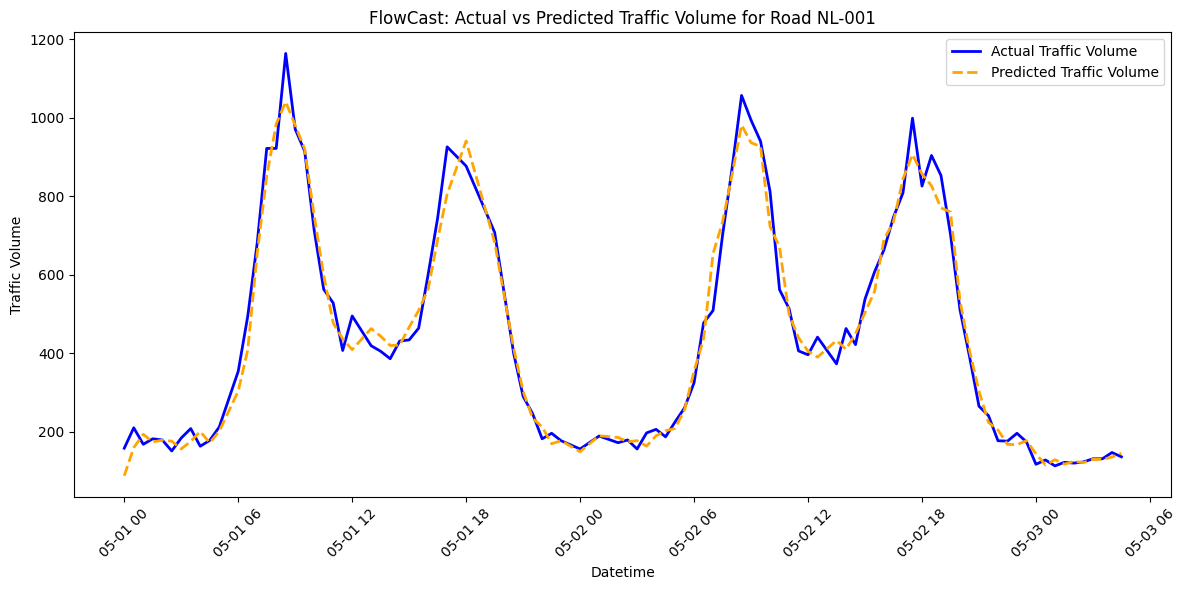

In [16]:
# Create a results DataFrame for comparison
results_df = test_df.copy()
results_df["predicted_traffic_volume"] = y_pred_reg
results_df["predicted_congestion_level"] = y_pred_clf

# Plot actual vs predicted traffic volume for a single road segment (e.g., NL-001)
sample_road = "NL-001"
sample_data = results_df[results_df["road_id"] == sample_road].head(96)  # 2 days of 30-min windows

plt.figure(figsize=(12, 6))
plt.plot(
    sample_data["datetime"],
    sample_data["traffic_volume"],
    label="Actual Traffic Volume",
    color="blue",
    linewidth=2,
)
plt.plot(
    sample_data["datetime"],
    sample_data["predicted_traffic_volume"],
    label="Predicted Traffic Volume",
    color="orange",
    linestyle="--",
    linewidth=2,
)
plt.title(f"FlowCast: Actual vs Predicted Traffic Volume for Road {sample_road}")
plt.xlabel("Datetime")
plt.ylabel("Traffic Volume")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
import joblib
import os

# Ensure output directories exist
os.makedirs("models", exist_ok=True)

# Save the trained LightGBM models
joblib.dump(reg_model, "models/flowcast_volume_regressor.pkl")
joblib.dump(clf_model, "models/flowcast_congestion_classifier.pkl")

# Export test predictions to CSV for reporting or dashboarding
results_df.to_csv("data/processed/flowcast_test_predictions.csv", index=False)

print("Models saved successfully to 'models/' directory.")
print("Test predictions exported to 'data/processed/flowcast_test_predictions.csv'.")

Models saved successfully to 'models/' directory.
Test predictions exported to 'data/processed/flowcast_test_predictions.csv'.


In [19]:
import joblib
import pandas as pd

# 1. Load saved models
reg_model = joblib.load("models/flowcast_volume_regressor.pkl")
clf_model = joblib.load("models/flowcast_congestion_classifier.pkl")


def predict_traffic(input_data: pd.DataFrame):
  """Takes a DataFrame with the required feature columns and returns predictions."""
  feature_cols = [
      "latitude",
      "longitude",
      "hour",
      "hour_of_day",
      "day_of_week",
      "is_weekend",
      "month",
      "temperature",
      "rainfall",
      "visibility",
      "public_holiday",
      "event_flag",
      "roadwork_flag",
      "road_capacity",
      "signal_timing",
      "2W",
      "Car",
      "LCV",
      "HCV",
      "traffic_vol_lag_30m",
      "traffic_vol_lag_1h",
  ]

  X = input_data[feature_cols]

  # Generate predictions
  vol_pred = reg_model.predict(X)
  cong_pred = clf_model.predict(X)

  results = input_data[["road_id", "datetime"]].copy()
  results["predicted_traffic_volume"] = vol_pred.round(0).astype(int)
  results["predicted_congestion_level"] = cong_pred

  return results


# Example usage with a sample slice from test data
if __name__ == "__main__":
  sample_input = pd.read_csv("data/processed/flowcast_test_predictions.csv").head(
      5
  )
  predictions = predict_traffic(sample_input)
  print(predictions)

  road_id             datetime  predicted_traffic_volume  \
0  NL-001  2025-05-01 00:00:00                        88   
1  NL-001  2025-05-01 00:30:00                       159   
2  NL-001  2025-05-01 01:00:00                       193   
3  NL-001  2025-05-01 01:30:00                       174   
4  NL-001  2025-05-01 02:00:00                       178   

  predicted_congestion_level  
0                  Free-flow  
1                  Free-flow  
2                  Free-flow  
3                  Free-flow  
4                  Free-flow  


In [20]:
from fastapi import FastAPI
import joblib
import pandas as pd
from pydantic import BaseModel

app = FastAPI(title="FlowCast Traffic Prediction API", version="1.0")

# Load models at startup
reg_model = joblib.load("models/flowcast_volume_regressor.pkl")
clf_model = joblib.load("models/flowcast_congestion_classifier.pkl")


# Define expected input schema
class TrafficInput(BaseModel):
  road_id: str
  latitude: float
  longitude: float
  hour: int
  hour_of_day: int
  day_of_week: int
  is_weekend: int
  month: int
  temperature: float
  rainfall: float
  visibility: float
  public_holiday: int
  event_flag: int
  roadwork_flag: int
  road_capacity: int
  signal_timing: int
  two_wheeler_share: float  # Mapped to '2W'
  car_share: float  # Mapped to 'Car'
  lcv_share: float  # Mapped to 'LCV'
  hcv_share: float  # Mapped to 'HCV'
  traffic_vol_lag_30m: float
  traffic_vol_lag_1h: float


@app.post("/predict")
def predict(data: TrafficInput):
  # Convert payload to DataFrame matching model feature names
  row = pd.DataFrame([{
      "latitude": data.latitude,
      "longitude": data.longitude,
      "hour": data.hour,
      "hour_of_day": data.hour_of_day,
      "day_of_week": data.day_of_week,
      "is_weekend": data.is_weekend,
      "month": data.month,
      "temperature": data.temperature,
      "rainfall": data.rainfall,
      "visibility": data.visibility,
      "public_holiday": data.public_holiday,
      "event_flag": data.event_flag,
      "roadwork_flag": data.roadwork_flag,
      "road_capacity": data.road_capacity,
      "signal_timing": data.signal_timing,
      "2W": data.two_wheeler_share,
      "Car": data.car_share,
      "LCV": data.lcv_share,
      "HCV": data.hcv_share,
      "traffic_vol_lag_30m": data.traffic_vol_lag_30m,
      "traffic_vol_lag_1h": data.traffic_vol_lag_1h,
  }])

  pred_vol = int(round(reg_model.predict(row)[0]))
  pred_cong = str(clf_model.predict(row)[0])

  return {
      "road_id": data.road_id,
      "predicted_traffic_volume": pred_vol,
      "predicted_congestion_level": pred_cong,
  }

In [22]:
"""
flowcast/
├── data/
│   ├── raw/                  # traffic_sensor_log.csv, weather_observations.csv, calendar_events.csv
│   └── processed/            # flowcast_analysis_ready.csv, flowcast_test_predictions.csv
├── models/
│   ├── flowcast_volume_regressor.pkl
│   └── flowcast_congestion_classifier.pkl
├── src/
│   ├── preprocess.py         # Steps 1-5: Cleaning & merging
│   ├── train.py              # Steps 6-12: Feature engineering, training & evaluation
│   └── predict.py            # Step 13: Batch/single inference
├── app.py                    # Step 14: FastAPI endpoint
└── requirements.txt          # pandas, numpy, scikit-learn, lightgbm, fastapi, uvicorn, joblib
"""

'\nflowcast/\n├── data/\n│   ├── raw/                  # traffic_sensor_log.csv, weather_observations.csv, calendar_events.csv\n│   └── processed/            # flowcast_analysis_ready.csv, flowcast_test_predictions.csv\n├── models/\n│   ├── flowcast_volume_regressor.pkl\n│   └── flowcast_congestion_classifier.pkl\n├── src/\n│   ├── preprocess.py         # Steps 1-5: Cleaning & merging\n│   ├── train.py              # Steps 6-12: Feature engineering, training & evaluation\n│   └── predict.py            # Step 13: Batch/single inference\n├── app.py                    # Step 14: FastAPI endpoint\n└── requirements.txt          # pandas, numpy, scikit-learn, lightgbm, fastapi, uvicorn, joblib\n'